In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("vgsales.csv")

In [3]:
# STEP 3: Explore the dataset
print("First 5 rows:")
print(df.head())


First 5 rows:
   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  


In [4]:
print("\nDataset shape:")
print(df.shape)


Dataset shape:
(16598, 11)


In [5]:
print("\nDataset information:")
df.info()



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [6]:
print("\nStatistical summary:")
print(df.describe())


Statistical summary:
               Rank          Year      NA_Sales      EU_Sales      JP_Sales  \
count  16598.000000  16327.000000  16598.000000  16598.000000  16598.000000   
mean    8300.605254   2006.406443      0.264667      0.146652      0.077782   
std     4791.853933      5.828981      0.816683      0.505351      0.309291   
min        1.000000   1980.000000      0.000000      0.000000      0.000000   
25%     4151.250000   2003.000000      0.000000      0.000000      0.000000   
50%     8300.500000   2007.000000      0.080000      0.020000      0.000000   
75%    12449.750000   2010.000000      0.240000      0.110000      0.040000   
max    16600.000000   2020.000000     41.490000     29.020000     10.220000   

        Other_Sales  Global_Sales  
count  16598.000000  16598.000000  
mean       0.048063      0.537441  
std        0.188588      1.555028  
min        0.000000      0.010000  
25%        0.000000      0.060000  
50%        0.010000      0.170000  
75%        0.0

In [7]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']


In [8]:
# STEP 4: Check missing values before cleaning
print("\nMissing values before cleaning:")
print(df.isnull().sum())

print("\nMissing value percentages:")
print((df.isnull().sum() / len(df)) * 100)



Missing values before cleaning:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Missing value percentages:
Rank            0.000000
Name            0.000000
Platform        0.000000
Year            1.632727
Genre           0.000000
Publisher       0.349440
NA_Sales        0.000000
EU_Sales        0.000000
JP_Sales        0.000000
Other_Sales     0.000000
Global_Sales    0.000000
dtype: float64


In [9]:
# STEP 5: Handle missing values
df.loc[:, 'Publisher'] = df['Publisher'].fillna('Unknown')

In [10]:
# STEP 6: Check and remove duplicate rows
print("\nDuplicate rows before removal:")
print(df.duplicated().sum())



Duplicate rows before removal:
0


In [11]:
# STEP 7: Correct the Year data type
df.loc[:, 'Year'] = df['Year'].astype('Int64')


C:\Users\Sanika\AppData\Local\Temp\ipykernel_24436\3362549601.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '<IntegerArray>
[2006, 1985, 2008, 2009, 1996, 1989, 2006, 2006, 2009, 1984,
 ...
 2008, 2016, 2007, 2004, 2008, 2002, 2003, 2008, 2010, 2003]
Length: 16598, dtype: Int64' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[:, 'Year'] = df['Year'].astype('Int64')


In [12]:
# STEP 8: Remove extra spaces from text columns
text_columns = df.select_dtypes(include=['object']).columns

for col in text_columns:
    df.loc[:, col] = df[col].str.strip()

In [13]:
# STEP 9: Check unique values
print("\nUnique platforms:")
print(df['Platform'].unique())

print("\nUnique genres:")
print(df['Genre'].unique())

print("\nNumber of unique genres:")
print(df['Genre'].nunique())




Unique platforms:
['Wii' 'NES' 'GB' 'DS' 'X360' 'PS3' 'PS2' 'SNES' 'GBA' '3DS' 'PS4' 'N64'
 'PS' 'XB' 'PC' '2600' 'PSP' 'XOne' 'GC' 'WiiU' 'GEN' 'DC' 'PSV' 'SAT'
 'SCD' 'WS' 'NG' 'TG16' '3DO' 'GG' 'PCFX']

Unique genres:
['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy']

Number of unique genres:
12


In [14]:
# STEP 10: Check negative sales values
sales_columns = [
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales',
    'Global_Sales'
]

print("\nNegative sales values:")
print((df[sales_columns] < 0).sum())


Negative sales values:
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


In [15]:
# STEP 11: Check Year range
print("\nMinimum and maximum release year:")
print(df['Year'].min(), df['Year'].max())



Minimum and maximum release year:
1980 2020


In [16]:
# STEP 12: Compare regional sales with global sales
regional_sales = df[
    ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
].sum(axis=1)

sales_difference = df['Global_Sales'] - regional_sales

print("\nSales difference summary:")
print(sales_difference.describe())



Sales difference summary:
count    16598.000000
mean         0.000277
std          0.005223
min         -0.020000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.020000
dtype: float64


In [17]:
# STEP 13: Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher         0
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


In [18]:
# STEP 14: Check final dataset shape
print("\nFinal dataset shape:")
print(df.shape)


Final dataset shape:
(16598, 11)


In [19]:
# STEP 15: Save the cleaned dataset
df.to_csv("vgsales_cleaned.csv", index=False)

print("\nData cleaning completed successfully!")
print("Cleaned dataset saved as vgsales_cleaned.csv")



Data cleaning completed successfully!
Cleaned dataset saved as vgsales_cleaned.csv


In [20]:
# importing the new cleaned dataset

In [21]:
df = pd.read_csv("vgsales_cleaned.csv")

In [22]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [23]:
df.shape

(16598, 11)

## Video game sales by genre

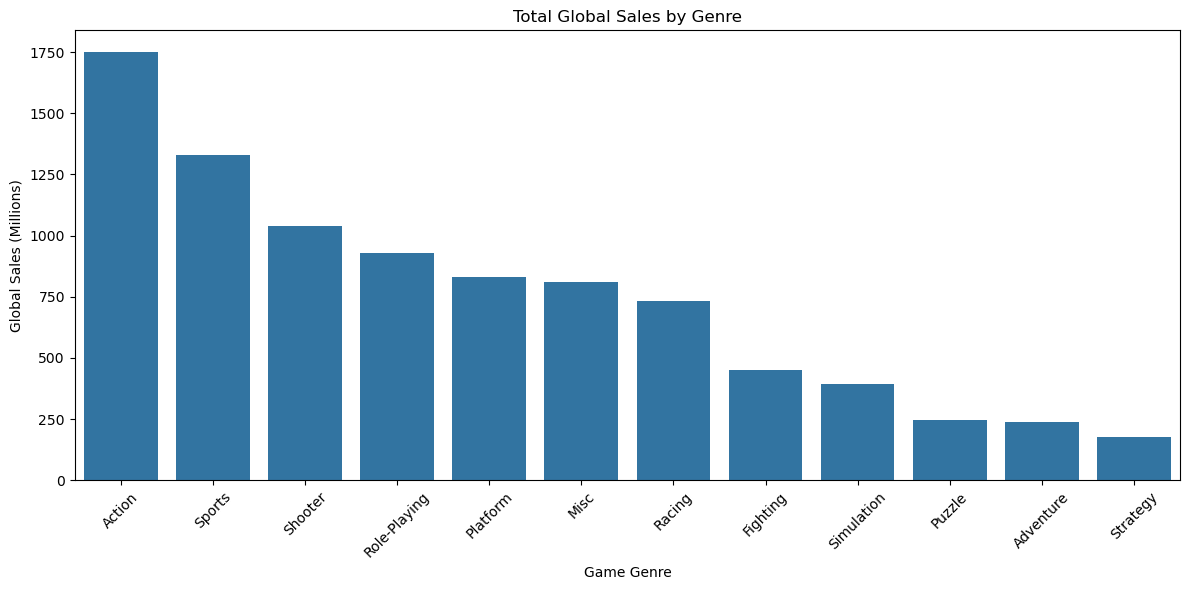

In [29]:

genre_sales = df.groupby('Genre')['Global_Sales'].sum()
genre_sales = genre_sales.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=genre_sales.index, y=genre_sales.values)

plt.title('Total Global Sales by Genre')
plt.xlabel('Game Genre')
plt.ylabel('Global Sales (Millions)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Top 10 Platforms by Global Sales

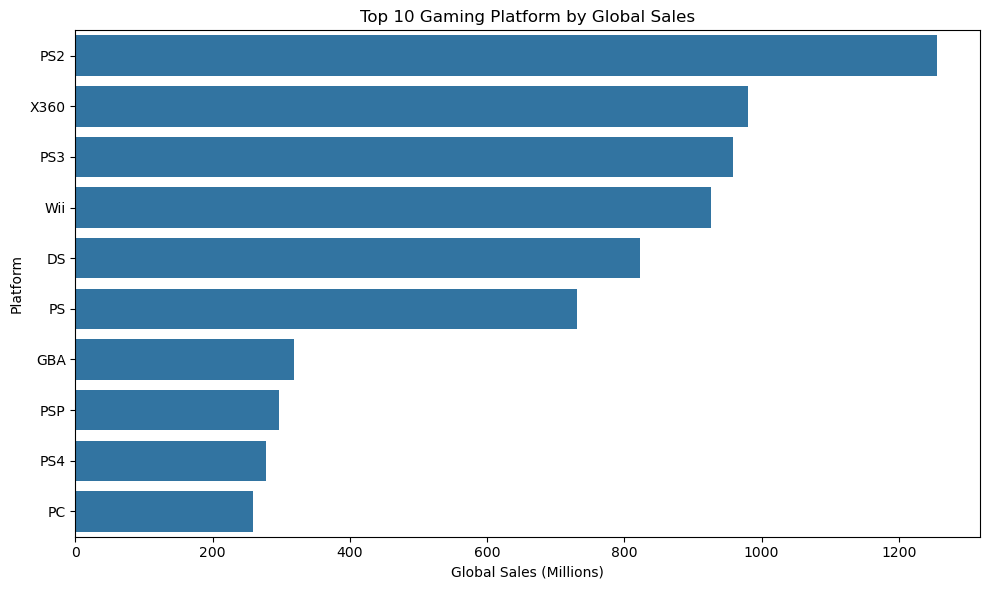

In [30]:
platform_sales = (
    df.groupby('Platform')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=platform_sales.values, y=platform_sales.index)

plt.title('Top 10 Gaming Platform by Global Sales')
plt.xlabel('Global Sales (Millions)')
plt.ylabel('Platform')
plt.tight_layout()
plt.show()

## Global video game sales over the years

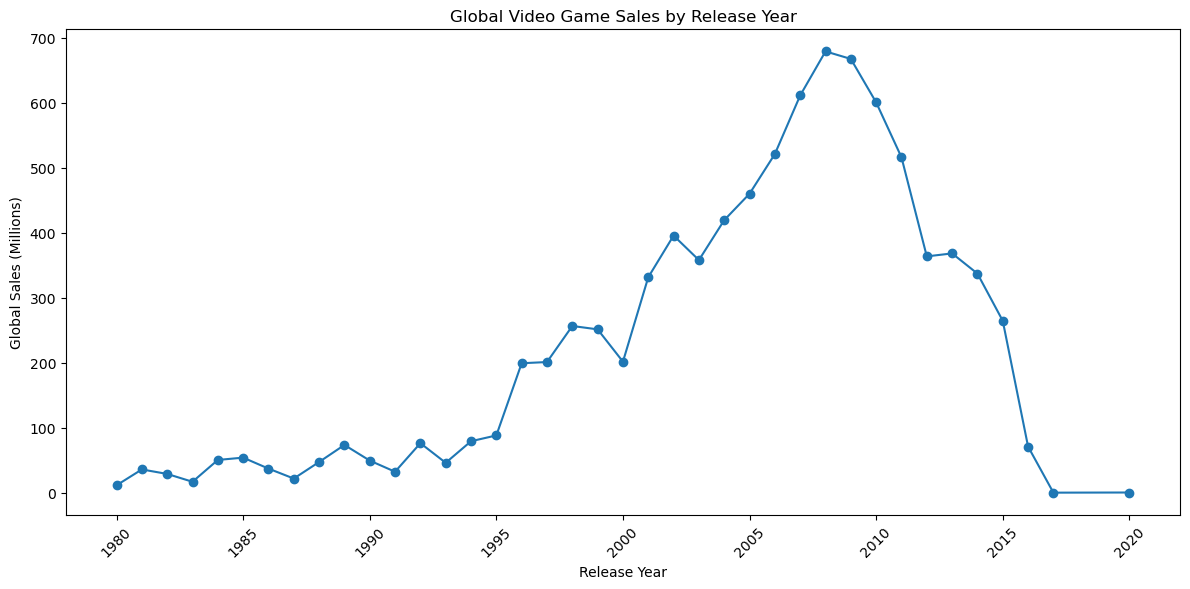

In [33]:

year_sales = (
    df.dropna(subset=['Year'])
    .groupby('Year')['Global_Sales']
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 6))
plt.plot(year_sales.index.astype(int), year_sales.values, marker='o')

plt.title('Global Video Game Sales by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Global Sales (Millions)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Top 10 best-selling video games

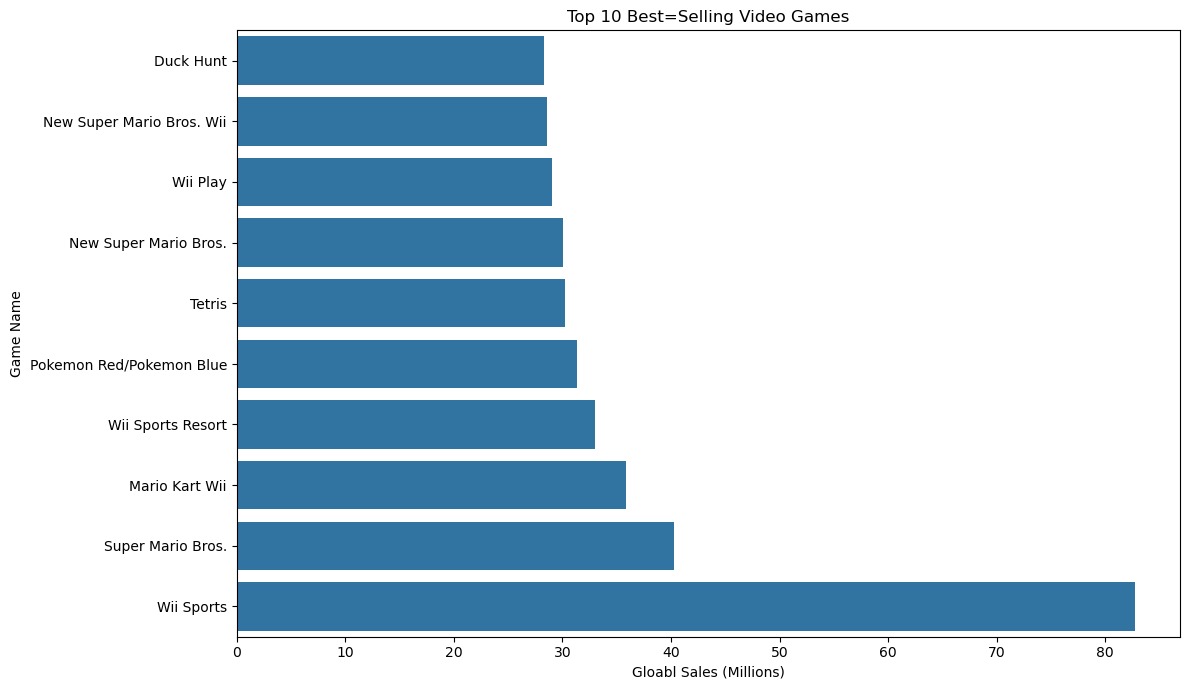

In [34]:
top_games = (
    df.nlargest(10, 'Global_Sales')
    .sort_values('Global_Sales', ascending = True)
)

plt.figure(figsize = (12,7))
sns.barplot(
    data = top_games,
    x = 'Global_Sales',
    y = 'Name'
)

plt.title('Top 10 Best=Selling Video Games')
plt.xlabel('Gloabl Sales (Millions)')
plt.ylabel('Game Name')
plt.tight_layout()
plt.show()

## Sales comparison by region

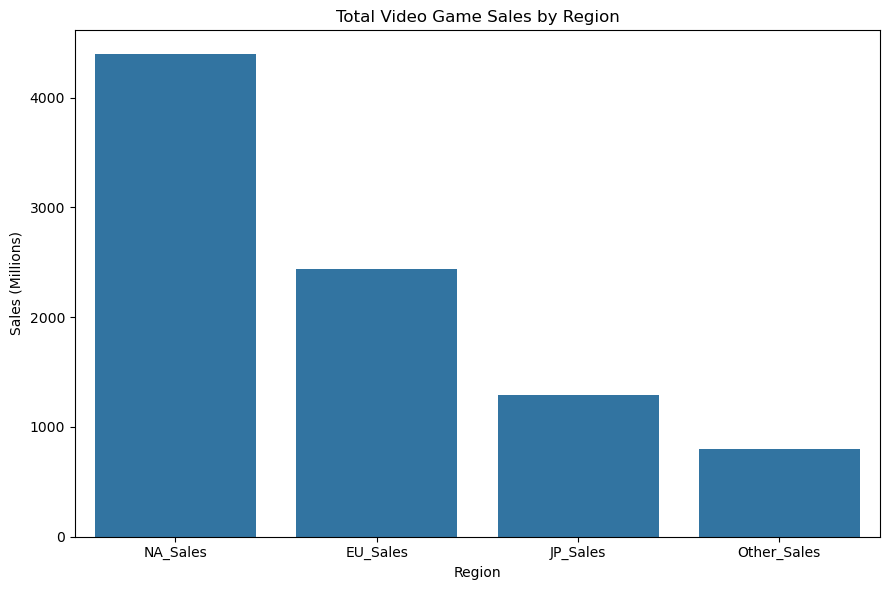

In [35]:
regional_total = df[
    ['NA_Sales','EU_Sales','JP_Sales','Other_Sales']

].sum()

plt.figure(figsize = (9,6))
sns.barplot(
    x = regional_total.index,
    y = regional_total.values
)

plt.title('Total Video Game Sales by Region')
plt.xlabel('Region')
plt.ylabel('Sales (Millions)')
plt.tight_layout()
plt.show()

## Distribution of global sales - histogram

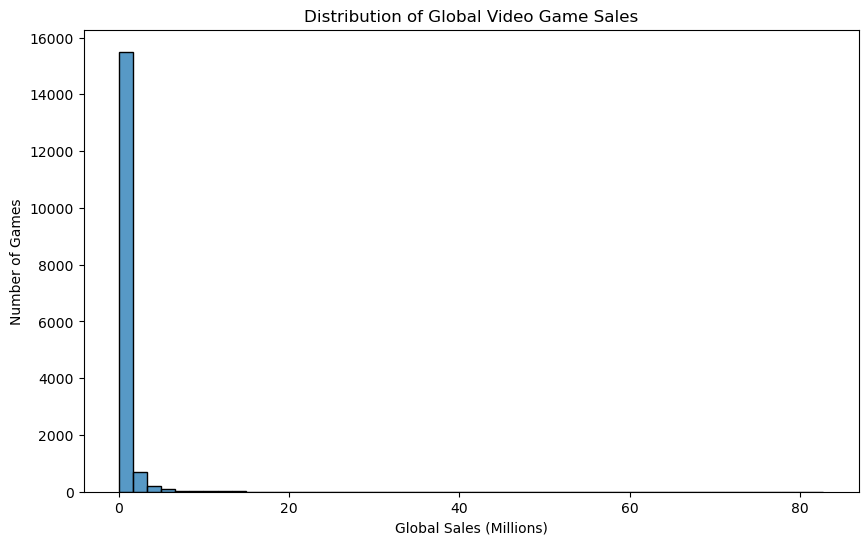

In [37]:
plt.figure(figsize = (10,6))
sns.histplot(
    data = df,
    x = 'Global_Sales',
    bins = 50
)
plt.title('Distribution of Global Video Game Sales')
plt.xlabel('Global Sales (Millions)')
plt.ylabel('Number of Games')
plt.show()

## Compare sales by genre - Box plot

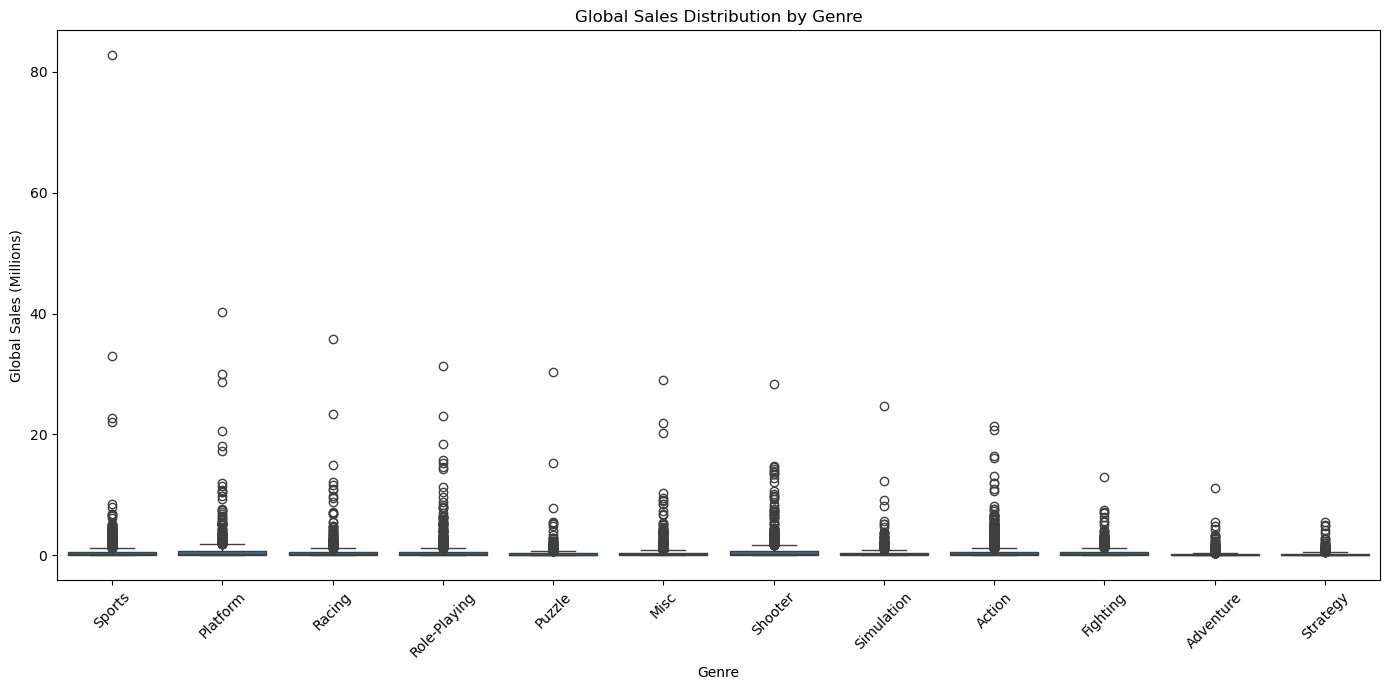

In [39]:
plt.figure(figsize=(14,7))

sns.boxplot(
    data = df,
    x = 'Genre',
    y = 'Global_Sales'
)
plt.title('Global Sales Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('Global Sales (Millions)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Top 10 Publishers by global sales

In [40]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')

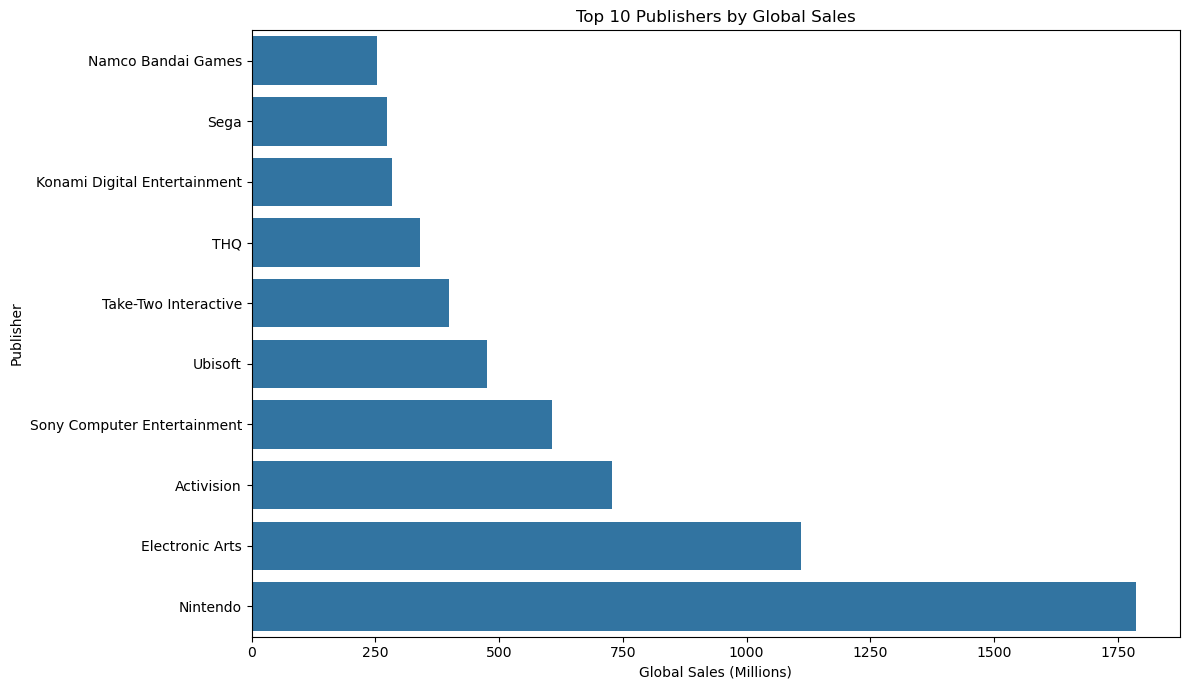

In [41]:
publisher_sales = (
    df[df['Publisher'] != 'Unknown'].groupby('Publisher')['Global_Sales'].sum
    ().sort_values(ascending=False).head(10).sort_values(ascending=True)
)

plt.figure(figsize=(12,7))

sns.barplot(
    x=publisher_sales.values,
    y=publisher_sales.index
)

plt.title('Top 10 Publishers by Global Sales')
plt.xlabel('Global Sales (Millions)')
plt.ylabel('Publisher')
plt.tight_layout()
plt.show()

## Correlation Heatmap

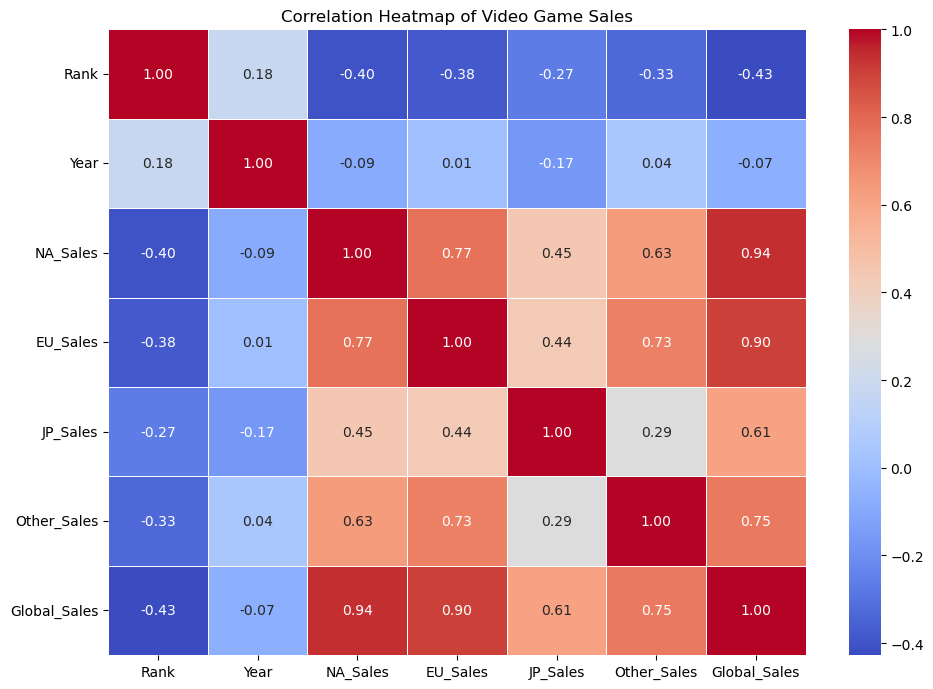

In [42]:
numeric_df = df.select_dtypes(include = 'number')

plt.figure(figsize= (10,7))
sns.heatmap(
    numeric_df.corr(),
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    linewidths = 0.5
)
plt.title('Correlation Heatmap of Video Game Sales')
plt.tight_layout()
plt.show()